In [8]:
%pip install pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
import pandas as pd
import numpy as np

In [10]:
df = pd.read_csv("../data/WA_Fn-UseC_-HR-Employee-Attrition.csv")
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [11]:
df_original = df.copy()

In [12]:
print("Dataset Information:")
print(df.info())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470

In [13]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values in Each Column:
Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCu

In [14]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 0


## 1. Handling Missing Values

Missing values are handled based on the type and importance of each column.

- Numerical columns: Fill missing values with median because
  the median is less affected by outliers.
- Categorical columns: Fill missing values with mode because
  it represents the most frequently occurring category.
- Important columns: If missing values cannot be reliably estimated,
  leave them missing and create a flag.
- Unnecessary columns: Drop only when the column is not useful
  for analysis.

The treatment decision should depend on the actual dataset.

In [15]:
for col in df.columns:

    if df[col].isnull().sum() > 0:

        if pd.api.types.is_numeric_dtype(df[col]):

            df[col] = df[col].fillna(df[col].median())

            print(col, "-> Missing values filled with median")

        else:

            mode_value = df[col].mode()

            if not mode_value.empty:
                df[col] = df[col].fillna(mode_value[0])

                print(col, "-> Missing values filled with mode")
            else:
                print(col, "-> Missing values left unchanged")

In [16]:
print("Missing Values After Treatment:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values After Treatment:
Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInC

## 2. Fixing Data Types

Data types are checked and corrected to ensure that each column
contains the appropriate type of data.

Examples:
- Date columns should be converted to datetime.
- Numerical values stored as text should be converted to numeric.
- Categorical columns should be converted to category where appropriate.

In [17]:
# Convert date column
if 'JoiningDate' in df.columns:
    df['JoiningDate'] = pd.to_datetime(
        df['JoiningDate'], errors='coerce'
    )

# Convert numerical columns
numeric_columns = ['Age', 'Salary']

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Convert categorical columns
categorical_columns = ['Department', 'Gender', 'City']

for col in categorical_columns:
    if col in df.columns:
        df[col] = df[col].astype('category')

print(df.dtypes)

Age                            int64
Attrition                        str
BusinessTravel                   str
DailyRate                      int64
Department                  category
DistanceFromHome               int64
Education                      int64
EducationField                   str
EmployeeCount                  int64
EmployeeNumber                 int64
EnvironmentSatisfaction        int64
Gender                      category
HourlyRate                     int64
JobInvolvement                 int64
JobLevel                       int64
JobRole                          str
JobSatisfaction                int64
MaritalStatus                    str
MonthlyIncome                  int64
MonthlyRate                    int64
NumCompaniesWorked             int64
Over18                           str
OverTime                         str
PercentSalaryHike              int64
PerformanceRating              int64
RelationshipSatisfaction       int64
StandardHours                  int64
S

## 3. Removing Duplicate Records

Duplicate records can affect the accuracy of data analysis.

The duplicated() function identifies duplicate rows,
and drop_duplicates() removes them.

We keep the first occurrence of each record.

In [18]:
duplicates_before = df.duplicated().sum()

print("Duplicates Before Cleaning:", duplicates_before)

df = df.drop_duplicates()

print("Duplicates After Cleaning:", df.duplicated().sum())

Duplicates Before Cleaning: 0
Duplicates After Cleaning: 0


## 4. Standardising Text Data

Text data may contain inconsistent formatting, such as:

- Extra spaces
- Uppercase and lowercase differences
- Inconsistent spelling or category formatting

We standardise text by removing unnecessary spaces
and converting text into a consistent format.

In [19]:
text_columns = df.select_dtypes(include=['object']).columns

for col in text_columns:

    df[col] = df[col].astype('string').str.strip()

    df[col] = df[col].str.title()

print(df[text_columns].head())

  Attrition     BusinessTravel EducationField                JobRole  \
0       Yes      Travel_Rarely  Life Sciences        Sales Executive   
1        No  Travel_Frequently  Life Sciences     Research Scientist   
2       Yes      Travel_Rarely          Other  Laboratory Technician   
3        No  Travel_Frequently  Life Sciences     Research Scientist   
4        No      Travel_Rarely        Medical  Laboratory Technician   

  MaritalStatus Over18 OverTime  
0        Single      Y      Yes  
1       Married      Y       No  
2        Single      Y      Yes  
3       Married      Y      Yes  
4       Married      Y       No  


C:\Users\Dell\AppData\Local\Temp\ipykernel_17708\2778495547.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df.select_dtypes(include=['object']).columns


## 5. Outlier Detection Using IQR Method

Outliers are values that are significantly different
from the other observations.

We use the Interquartile Range (IQR) method.

IQR = Q3 - Q1

Lower Bound = Q1 - 1.5 * IQR

Upper Bound = Q3 + 1.5 * IQR

Values below the lower bound or above the upper bound
are considered potential outliers.

We will identify outliers and decide whether to retain,
remove or cap them based on business context.

In [20]:
numeric_columns = df.select_dtypes(include=np.number).columns

for col in numeric_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\nColumn: {col}")
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))


Column: Age
Lower Bound: 10.5
Upper Bound: 62.5
Number of Outliers: 0

Column: DailyRate
Lower Bound: -573.0
Upper Bound: 2195.0
Number of Outliers: 0

Column: DistanceFromHome
Lower Bound: -16.0
Upper Bound: 32.0
Number of Outliers: 0

Column: Education
Lower Bound: -1.0
Upper Bound: 7.0
Number of Outliers: 0

Column: EmployeeCount
Lower Bound: 1.0
Upper Bound: 1.0
Number of Outliers: 0

Column: EmployeeNumber
Lower Bound: -1105.5
Upper Bound: 3152.5
Number of Outliers: 0

Column: EnvironmentSatisfaction
Lower Bound: -1.0
Upper Bound: 7.0
Number of Outliers: 0

Column: HourlyRate
Lower Bound: -5.625
Upper Bound: 137.375
Number of Outliers: 0

Column: JobInvolvement
Lower Bound: 0.5
Upper Bound: 4.5
Number of Outliers: 0

Column: JobLevel
Lower Bound: -2.0
Upper Bound: 6.0
Number of Outliers: 0

Column: JobSatisfaction
Lower Bound: -1.0
Upper Bound: 7.0
Number of Outliers: 0

Column: MonthlyIncome
Lower Bound: -5291.0
Upper Bound: 16581.0
Number of Outliers: 114

Column: MonthlyRate
L

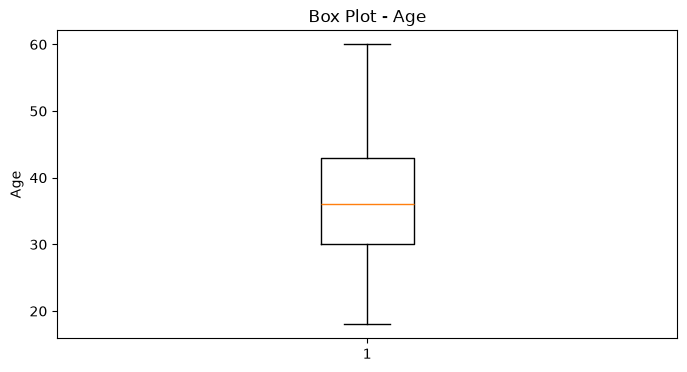

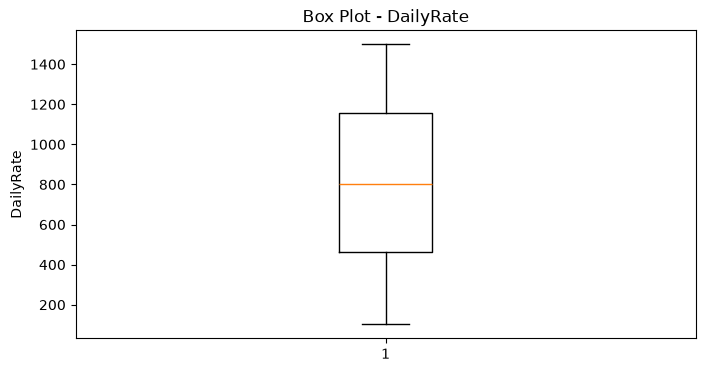

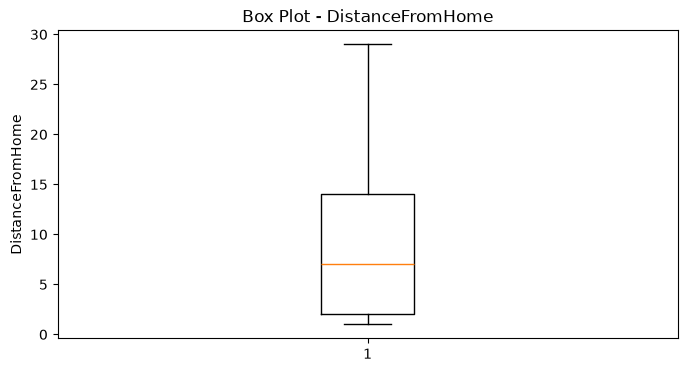

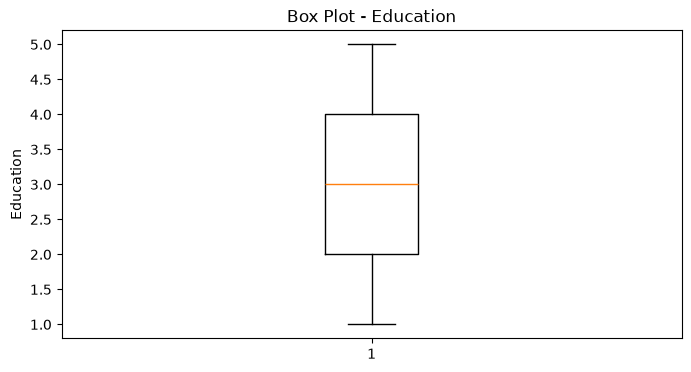

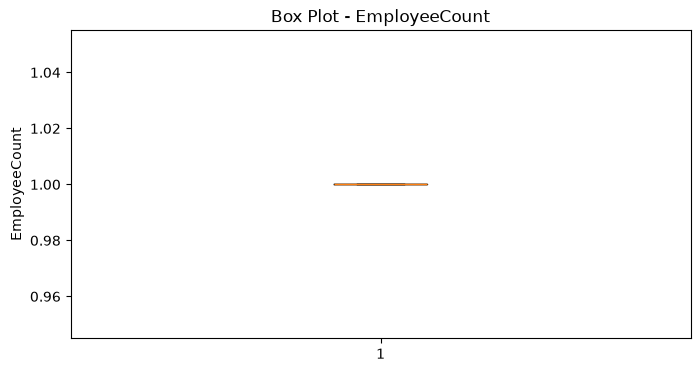

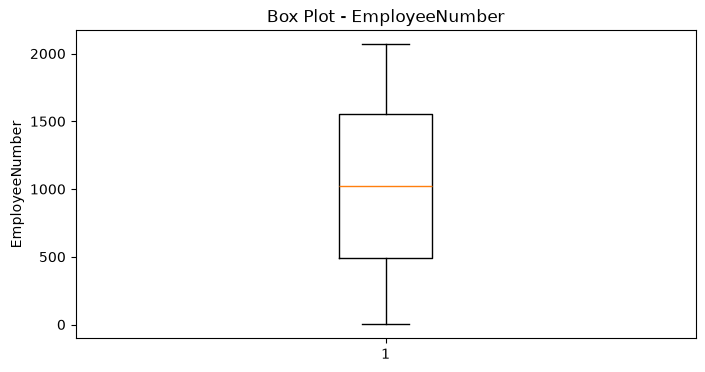

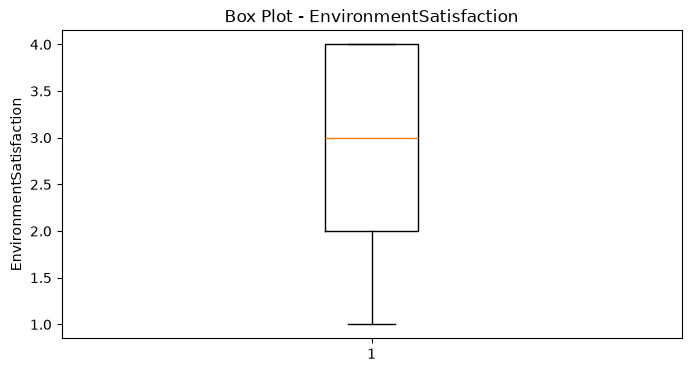

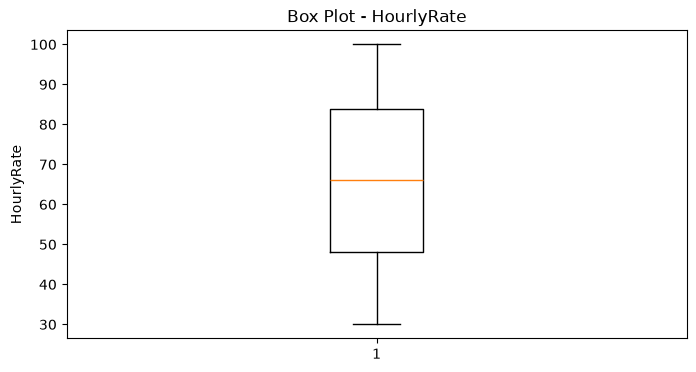

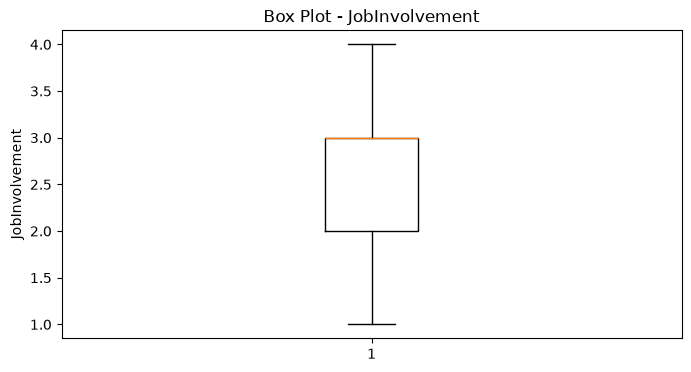

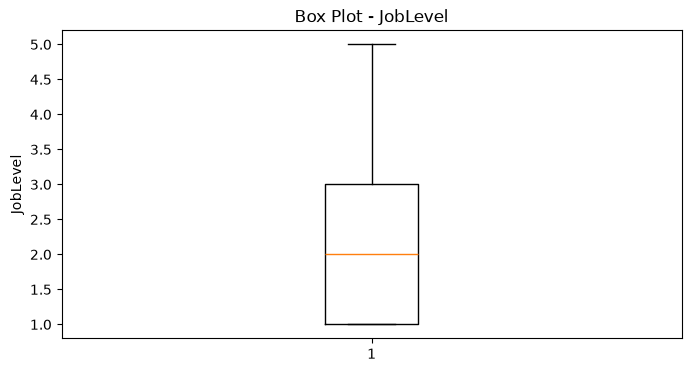

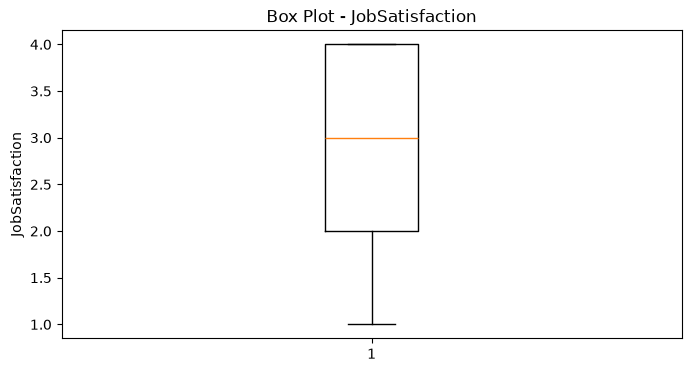

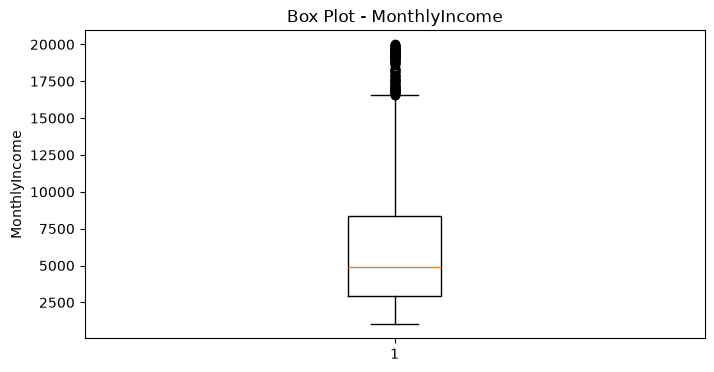

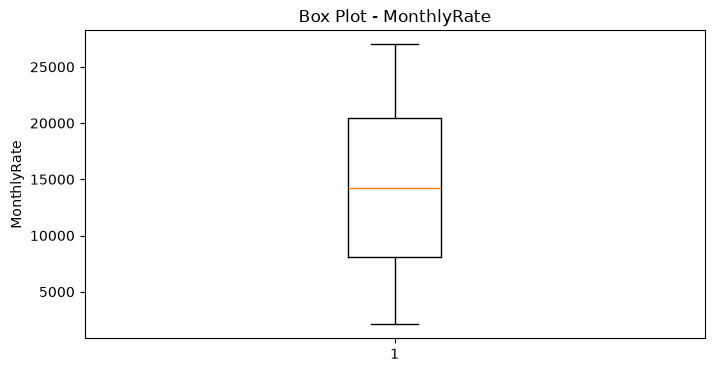

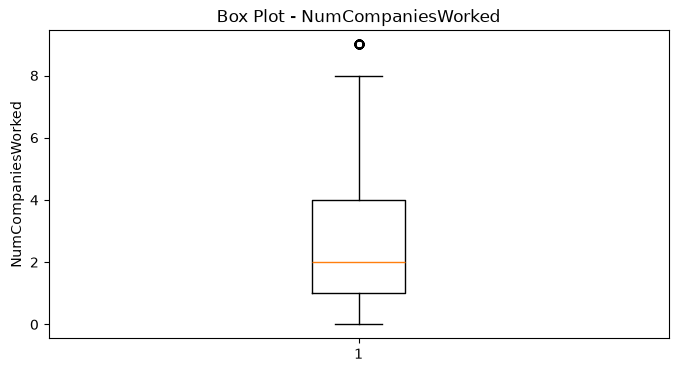

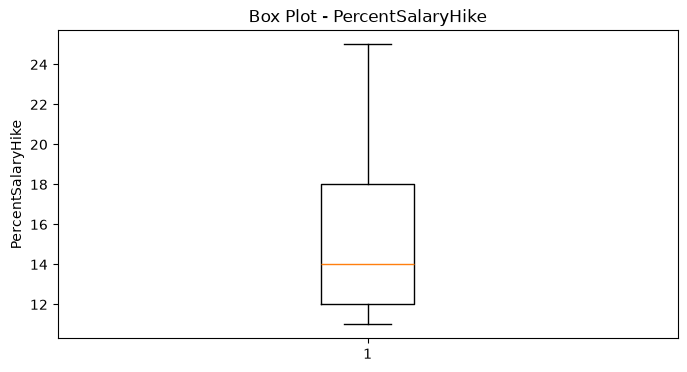

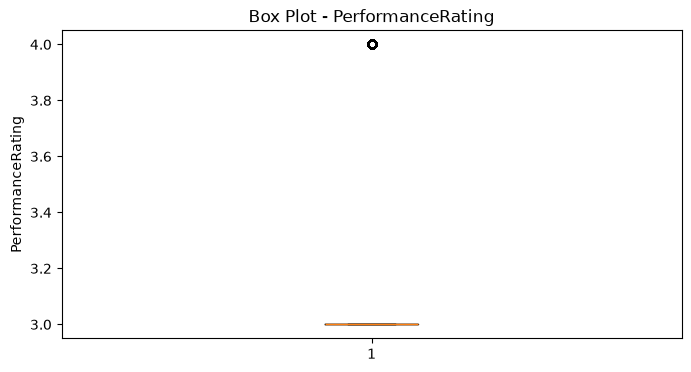

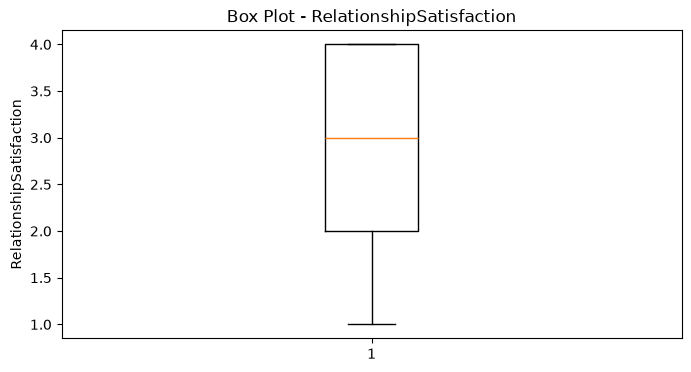

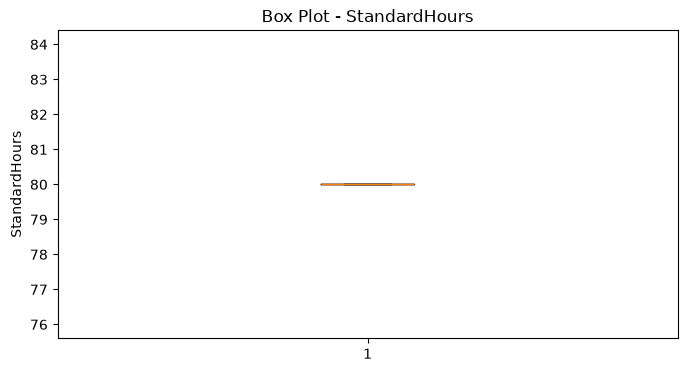

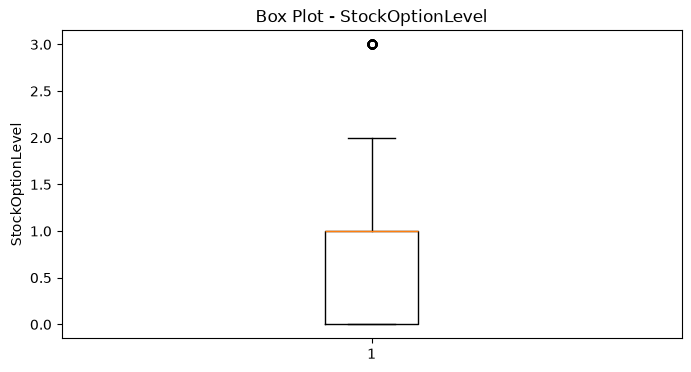

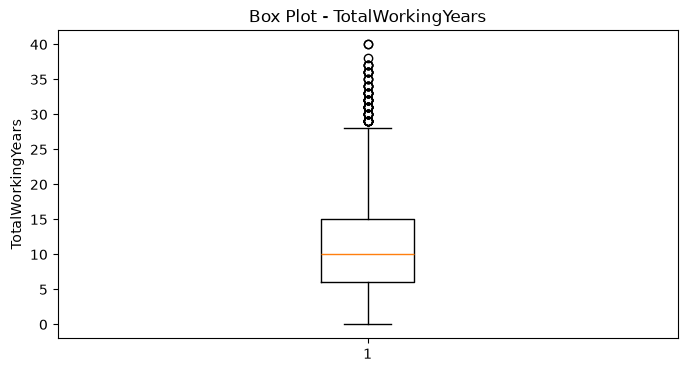

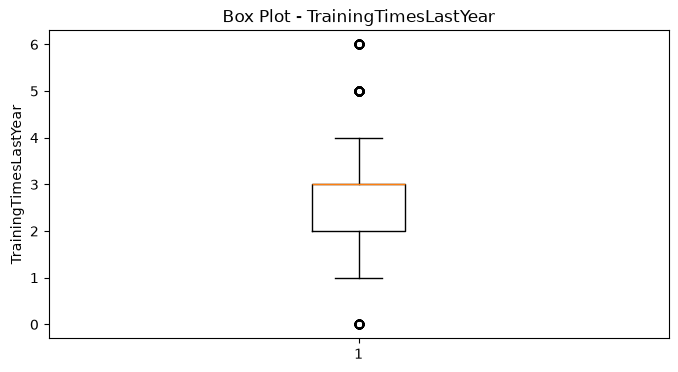

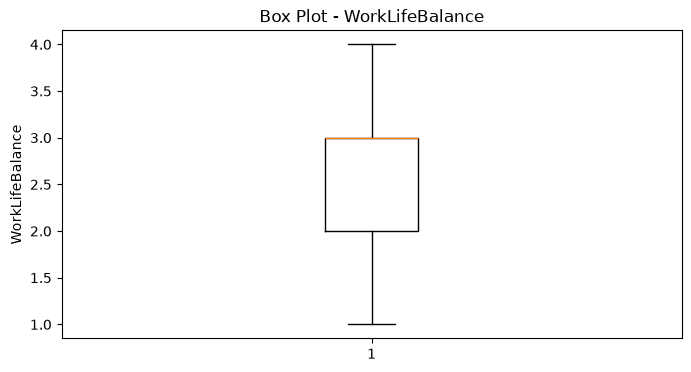

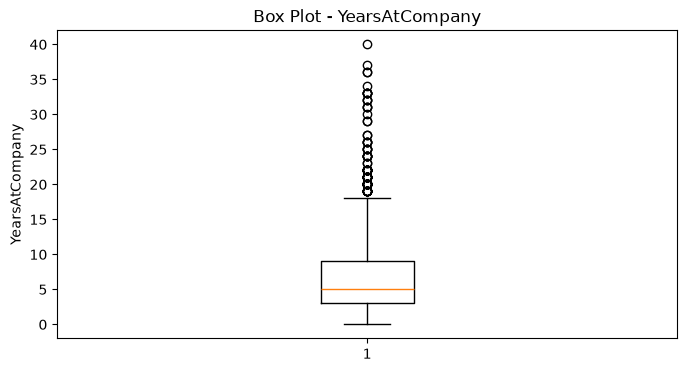

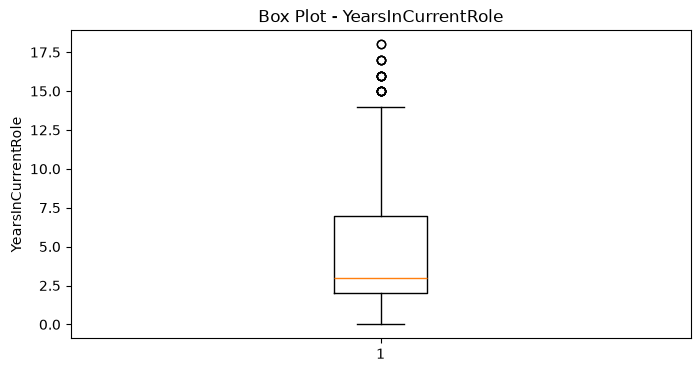

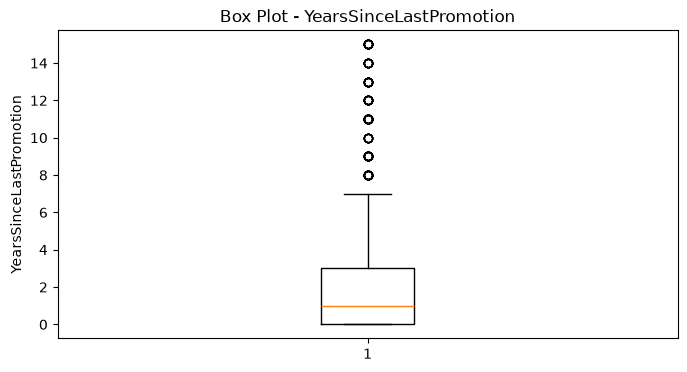

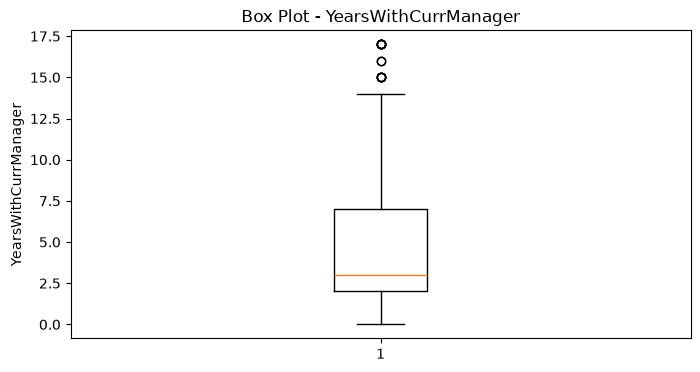

In [21]:
import matplotlib.pyplot as plt

for col in numeric_columns:

    plt.figure(figsize=(8, 4))

    plt.boxplot(df[col].dropna())

    plt.title(f"Box Plot - {col}")
    plt.ylabel(col)

    plt.show()

## 6. Outlier Treatment

After detecting outliers using the IQR method,
we should not automatically delete all outliers.

Outliers may represent genuine employee information,
such as a high salary or long work experience.

Decision:
- Genuine values: Retain them.
- Incorrect values: Correct or remove them if verified.
- Extreme values affecting analysis: Consider capping
  them after understanding the business context.

In this project, potential outliers are identified and
retained unless they are confirmed to be incorrect.

In [22]:
before_rows = len(df_original)
after_rows = len(df)

before_missing = df_original.isnull().sum().sum()
after_missing = df.isnull().sum().sum()

before_duplicates = df_original.duplicated().sum()
after_duplicates = df.duplicated().sum()

summary = pd.DataFrame({
    'Metric': ['Rows', 'Missing Values', 'Duplicates'],
    'Before Cleaning': [
        before_rows,
        before_missing,
        before_duplicates
    ],
    'After Cleaning': [
        after_rows,
        after_missing,
        after_duplicates
    ]
})

summary

,Metric,Before Cleaning,After Cleaning
0,Rows,1470,1470
1,Missing Values,0,0
2,Duplicates,0,0


In [25]:
before_rows = len(df_original)
after_rows = len(df)

before_missing = df_original.isnull().sum().sum()
after_missing = df.isnull().sum().sum()

before_duplicates = df_original.duplicated().sum()
after_duplicates = df.duplicated().sum()

summary = pd.DataFrame({
    'Metric': ['Rows', 'Missing Values', 'Duplicates'],
    'Before Cleaning': [
        before_rows,
        before_missing,
        before_duplicates
    ],
    'After Cleaning': [
        after_rows,
        after_missing,
        after_duplicates
    ]
})

print(f"Rows {before_rows} -> {after_rows} | "
      f"Missing values {before_missing} -> {after_missing} | "
      f"Duplicates {before_duplicates} -> {after_duplicates}")

Rows 1470 -> 1470 | Missing values 0 -> 0 | Duplicates 0 -> 0


In [23]:
print("Final Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nFinal Data Types:")
print(df.dtypes)

print("\nFirst 5 Cleaned Records:")
display(df.head())

Final Dataset Shape: (1470, 35)

Missing Values:
0

Duplicate Rows:
0

Final Data Types:
Age                            int64
Attrition                     string
BusinessTravel                string
DailyRate                      int64
Department                  category
DistanceFromHome               int64
Education                      int64
EducationField                string
EmployeeCount                  int64
EmployeeNumber                 int64
EnvironmentSatisfaction        int64
Gender                      category
HourlyRate                     int64
JobInvolvement                 int64
JobLevel                       int64
JobRole                       string
JobSatisfaction                int64
MaritalStatus                 string
MonthlyIncome                  int64
MonthlyRate                    int64
NumCompaniesWorked             int64
Over18                        string
OverTime                      string
PercentSalaryHike              int64
PerformanceRating      

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [24]:
df.to_csv("clean_data.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


## 7. Conclusion

The employee/customer dataset was cleaned successfully.

The following operations were performed:

1. Identified and handled missing values.
2. Corrected inappropriate data types.
3. Removed duplicate records.
4. Standardised text columns.
5. Detected potential outliers using the IQR method.
6. Created a before-and-after cleaning summary.
7. Exported the cleaned dataset as clean_data.csv.

The cleaned dataset is now ready for further analysis.